# Treinamento da BearingCNN no Dataset XJTU-SY

**Projeto:** Diagnóstico de Falhas em Rolamentos Industriais via CWT + CNN  
**Dataset:** Xi'an Jiaotong University (XJTU-SY — 25.6 kHz, Ensaio Run-to-Failure)  
**Classes:** 3 Classes (`normal`, `inner_race`, `outer_race`)  
**Objetivo:** Treinar do zero a arquitetura convolucional própria `BearingCNN` (com *Global Average Pooling*) sobre escalogramas CWT gerados a partir dos sinais de vibração do XJTU-SY.

---


## 1. Importação de Módulos e Configurações


In [1]:
import sys
from pathlib import Path

BASE_DIR = Path.cwd().parent.parent if Path.cwd().name in ['1_cwru', '2_paderborn', '3_xjtu', '4_cross_domain_tempo', '5_order_tracking', '6_confronto_final'] else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

from src.config import (
    XJTU_PROCESSED_DIR,
    NUM_EPOCHS,
    LEARNING_RATE,
    RANDOM_SEED,
    set_seed
)
from src.cnn_processor import train_and_evaluate_bearing_cnn
from src.visualization import plot_training_curves, plot_confusion_matrix

set_seed(RANDOM_SEED)

## 2. Treinamento da BearingCNN com Checkpointing Automático


In [2]:
# Treinamento de 10 épocas da BearingCNN com salvamento automático do melhor modelo (val_loss)
resultado_cnn = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=XJTU_PROCESSED_DIR,
    checkpoint_name="checkpoint_xjtu_bearing_cnn_best.pth"
)


[INFO] EXPERIMENTO BEARING CNN (PRÓPRIA) | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.8191 - Acc: 75.42% | Val Loss: 0.7679 - Acc: 80.19% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.5402 - Acc: 87.92% | Val Loss: 0.3856 - Acc: 93.89% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.3977 - Acc: 92.50% | Val Loss: 0.2514 - Acc: 94.81% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.3233 - Acc: 92.50% | Val Loss: 0.2503 - Acc: 92.59% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.2627 - Acc: 94.03% | Val Loss: 0.2130 - Acc: 93.15% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.2158 - Acc: 95.28% | Val Loss: 0.1834 - Acc: 95.00% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.1770 - Acc: 96.25% | Val Loss: 0.1963 - Acc: 94.07% 
Época [08/10] | Treino Loss: 0.1557 - Acc: 98.06% | Val Loss: 0.22

## 3. Curvas de Aprendizado (Loss e Acurácia)


[INFO] Figura salva em: ../../docs/images/training_curves_xjtu_bearing_cnn.png


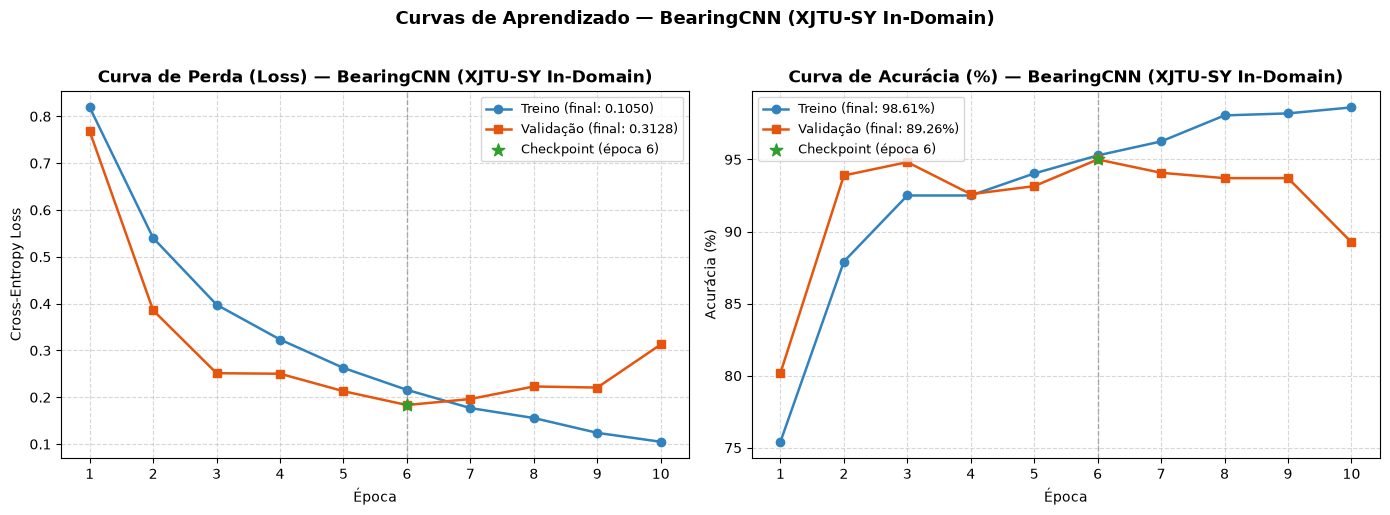

In [3]:
plot_training_curves(
    history=resultado_cnn["history"],
    model_name="BearingCNN (XJTU-SY In-Domain)",
    save_path="../../docs/images/training_curves_xjtu_bearing_cnn.png"
)


## 4. Matriz de Confusão e Relatório de Classificação no Conjunto de Teste


 RELATÓRIO DE CLASSIFICAÇÃO NO TESTE — BEARINGCNN (XJTU-SY)
              precision    recall  f1-score   support

  inner_race     0.9600    0.1600    0.2743       150
      normal     1.0000    0.9933    0.9967       150
  outer_race     0.5435    1.0000    0.7042       150

    accuracy                         0.7178       450
   macro avg     0.8345    0.7178    0.6584       450
weighted avg     0.8345    0.7178    0.6584       450

[INFO] Figura salva em: ../../docs/images/confusion_matrix_xjtu_bearing_cnn.png


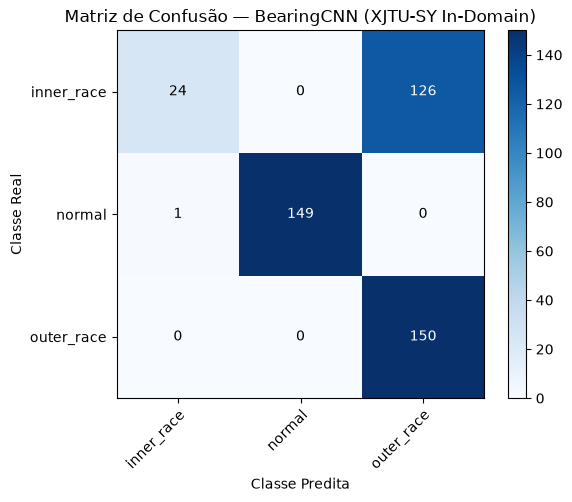

In [4]:
y_true = resultado_cnn["test_labels"]
y_pred = resultado_cnn["test_preds"]
class_names = resultado_cnn["classes"]

print("=" * 65)
print(" RELATÓRIO DE CLASSIFICAÇÃO NO TESTE — BEARINGCNN (XJTU-SY)")
print("=" * 65)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

plot_confusion_matrix(
    res=resultado_cnn,
    model_name="BearingCNN (XJTU-SY In-Domain)",
    save_path="../../docs/images/confusion_matrix_xjtu_bearing_cnn.png"
)
